## TRANSFER ANALYSIS
Using the Premier League transfer data collected from 2016 until 2026, this notebook will investigate trends in Premier League team's transfer incomings over that period. The aim is to understand which nations and leagues Premier League teams tend to buy from and the sort of how transfer fees vary between these nationalities and leagues. From this I will be able to investigate if certain leagues are overlooking for recruitment. 

In [1]:
import pandas as pd
from pathlib import Path

project_folder = Path.cwd().parent
transfers_df = pd.read_csv(project_folder / "data/cleaned/transfers.csv")

### Nationalities
The first investigation will look at the distribution of nationalities of Premier League signings between summer 2016 and summer 2026.

In [4]:
# Identify every unique nationality in the transfer data
print(transfers_df["nationality"].unique().tolist())

# Convert nationalities to ISO-3 codes for compatability with plotly
country_codes = {
    "England": "GBR",
    "France": "FRA",
    "Australia": "AUS",
    "Ireland": "IRL",
    "Netherlands": "NLD",
    "United States": "USA",
    "Switzerland": "CHE",
    "Germany": "DEU",
    "Spain": "ESP",
    "Japan": "JPN",
    "Belgium": "BEL",
    "Iceland": "ISL",
    "Brazil": "BRA",
    "Portugal": "PRT",
    "Serbia": "SRB",
    "Ghana": "GHA",
    "DR Congo": "COD",
    "Wales": "GBR",
    "Senegal": "SEN",
    "Ecuador": "ECU",
    "Nigeria": "NGA",
    "Scotland": "GBR",
    "Norway": "NOR",
    "Poland": "POL",
    "Italy": "ITA",
    "Algeria": "DZA",
    "Mali": "MLI",
    "Estonia": "EST",
    "Cameroon": "CMR",
    "Austria": "AUT",
    "Chile": "CHL",
    "Colombia": "COL",
    "Argentina": "ARG",
    "Ukraine": "UKR",
    "Venezuela": "VEN",
    "Armenia": "ARM",
    "Cote d'Ivoire": "CIV",
    "Sweden": "SWE",
    "Denmark": "DNK",
    "Uruguay": "URY",
    "Benin": "BEN",
    "Morocco": "MAR",
    "Tunisia": "TUN",
    "Egypt": "EGY",
    "Burundi": "BDI",
    "Gabon": "GAB",
    "Northern Ireland": "GBR",
    "South Africa": "ZAF",
    "Costa Rica": "CRI",
    "New Zealand": "NZL",
    "Kenya": "KEN",
    "Jamaica": "JAM",
    "Zimbabwe": "ZWE",
    "Türkiye": "TUR",
    "Bosnia-Herzegovina": "BIH",
    "Greece": "GRC",
    "Czech Republic": "CZE",
    "Curacao": "CUW",
    "Bermuda": "BMU",
    "North Macedonia": "MKD",
    "Croatia": "HRV",
    "Kosovo": "UNK",
    "Slovakia": "SVK",
    "Guadeloupe": "GLP",
    "Peru": "PER",
    "China": "CHN",
    "Mexico": "MEX",
    "Montenegro": "MNE",
    "Iran": "IRN",
    "Romania": "ROU",
    "Slovenia": "SVN",
    "Guinea": "GIN",
    "Korea, South": "KOR",
    "Paraguay": "PRY",
    "Tanzania": "TZA",
    "Azerbaijan": "AZE",
    "Burkina Faso": "BFA",
    "Angola": "AGO",
    "Zambia": "ZMB",
    "Nicaragua": "NIC",
    "Dominican Republic": "DOM",
    "Albania": "ALB",
    "Hungary": "HUN",
    "Israel": "ISR",
    "Syria": "SYR",
    "Haiti": "HTI",
    "Guinea-Bissau": "GNB",
    "The Gambia": "GMB",
    "Canada": "CAN",
    "Georgia": "GEO",
    "Uzbekistan": "UZB",
    "Sierra Leone": "SLE",
    "Cyprus": "CYP",
    "Mozambique": "MOZ",
    "Kazakhstan": "KAZ",
}

# Create new col and apply mapping
transfers_df["country_code"] = transfers_df["nationality"].map(country_codes)

['England', 'France', 'Australia', 'Ireland', 'Netherlands', 'United States', 'Switzerland', 'Germany', 'Spain', 'Japan', 'Belgium', 'Iceland', 'Brazil', 'Portugal', 'Serbia', 'Ghana', 'DR Congo', 'Wales', 'Senegal', 'Ecuador', 'Nigeria', 'Scotland', 'Norway', 'Poland', 'Italy', 'Algeria', 'Mali', 'Estonia', 'Cameroon', 'Austria', 'Chile', 'Colombia', 'Argentina', 'Ukraine', 'Venezuela', 'Armenia', "Cote d'Ivoire", 'Sweden', 'Denmark', 'Uruguay', 'Benin', 'Morocco', 'Tunisia', 'Egypt', 'Burundi', 'Gabon', 'Northern Ireland', 'South Africa', 'Costa Rica', 'New Zealand', 'Kenya', 'Jamaica', 'Zimbabwe', 'Türkiye', 'Bosnia-Herzegovina', 'Greece', 'Czech Republic', 'Curacao', 'Bermuda', 'North Macedonia', 'Croatia', 'Kosovo', 'Slovakia', 'Guadeloupe', 'Peru', 'China', 'Mexico', 'Montenegro', 'Iran', 'Romania', 'Slovenia', 'Guinea', 'Korea, South', 'Paraguay', 'Tanzania', 'Azerbaijan', 'Burkina Faso', 'Angola', 'Zambia', 'Nicaragua', 'Dominican Republic', 'Albania', 'Hungary', 'Israel', 'Syr

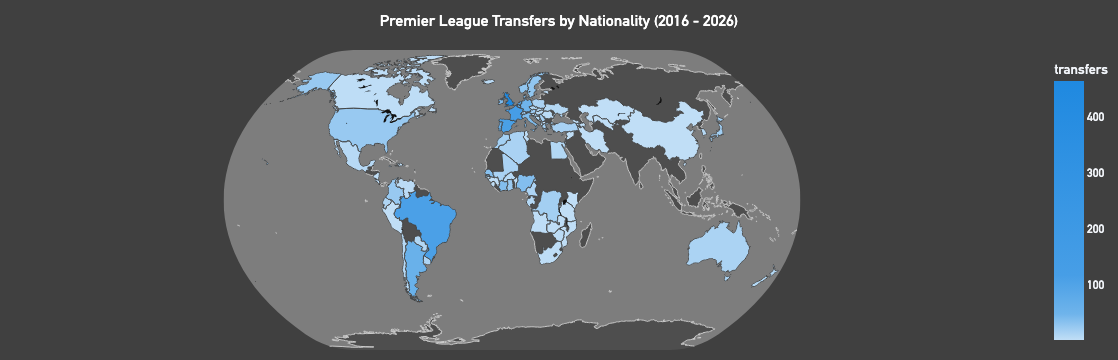

In [26]:
import pandas as pd
import plotly.express as px

# --------------------------------------------------
# 1. Prepare the data
# --------------------------------------------------

#Aggregate transfer data by nationality
map_stats = (transfers_df.dropna(subset = ["country_code"])
                             .groupby(["country_code"])
                             .agg(transfers = ("player_name", "size"),
                                  avg_fee = ("fee", "mean")).reset_index())

# Get the three most expensive transfers for each country
top_transfers = (transfers_df.dropna(subset=["country_code", "fee"])
                             .sort_values("fee", ascending=False)
                             .groupby("country_code")
                             .head(3)
                             .groupby("country_code")
                             .apply(lambda group: "<br>".join(f"{row['player_name']}: €{row['fee']:,.0f}"
                                                              for _, row in group.iterrows()),
                                    include_groups=False)
                             .rename("top_3_transfers")
                             .reset_index())

# Add top transfers to the map data
map_stats = map_stats.merge(top_transfers,
                            on = "country_code",
                            how = "left")

# Map ISO codes to country names
country_names = (transfers_df.dropna(subset=["country_code"])
                             .drop_duplicates("country_code")
                             .set_index("country_code")["nationality"]
                             .to_dict())
map_stats["country_name"] = map_stats["country_code"].map(country_names)

# --------------------------------------------------
# 2. Create the map
# --------------------------------------------------

fig = px.choropleth(
    map_stats,
    locations = "country_code",
    locationmode = "ISO-3",
    color = "transfers",
    color_continuous_scale = [[0.0, "#C0DEF6"],
    [0.05, "#98C9F1"],
    [0.1, "#6FB4EB"],
    [0.25, "#479EE6"],
    [1.0, "#1F89E0"]],
    custom_data = ["country_name",
                   "avg_fee",
                   "top_3_transfers"],
    projection="natural earth")

# --------------------------------------------------
# 3. Customise hover information
# --------------------------------------------------

fig.update_traces(
    hovertemplate=(
        "<b>%{customdata[0]}</b><br>"
        "Total transfers: %{z:,.0f}<br>"
        "Average transfer fee: €%{customdata[1]:,.0f}<br>"
        "<br><b>Top 3 most expensive transfers</b><br>"
        "%{customdata[2]}"
        "<extra></extra>"))

# --------------------------------------------------
# 4. Style the chart
# --------------------------------------------------

fig.update_layout(
    font_family="DIN Alternate",
    template = "plotly_dark",
    paper_bgcolor="#404040",
    plot_bgcolor="#404040",
    geo = dict(
        showframe = False,
        showcoastlines = True,
        coastlinecolor = "#CCCCCC",
        showland = True,
        landcolor = "#4E4E4E",
        showocean = True,
        oceancolor = "#7D7D7D",
        bgcolor = "#404040",
    ),

    title=dict(
        text="Premier League Transfers by Nationality (2016 - 2026)",
        font=dict(
            family="DIN Alternate",
            size=16,
            color="#FFFFFF"
        ),
        x = 0.5,               # Centre horizontally
        xanchor = "center",
        y= 0.96 ,              # Vertical position
        yanchor="top"
    ),
    
    margin = dict(l = 0, r = 0, t = 50, b = 10),
    height = None,
    autosize = True)

# --------------------------------------------------
# 5. Export file as html
# --------------------------------------------------

fig.write_html(project_folder / "figures/html/nationalities-map.html",
               config = {"responsive" : True,
                         "displayModeBar" : False})

# --------------------------------------------------
# 6. Display the chart
# --------------------------------------------------

fig.show()


In [12]:
continent_mapping = {
    # Europe
    "England": "Europe",
    "France": "Europe",
    "Ireland": "Europe",
    "Netherlands": "Europe",
    "Switzerland": "Europe",
    "Germany": "Europe",
    "Spain": "Europe",
    "Belgium": "Europe",
    "Iceland": "Europe",
    "Portugal": "Europe",
    "Serbia": "Europe",
    "Wales": "Europe",
    "Scotland": "Europe",
    "Norway": "Europe",
    "Poland": "Europe",
    "Italy": "Europe",
    "Estonia": "Europe",
    "Austria": "Europe",
    "Ukraine": "Europe",
    "Armenia": "Asia",
    "Sweden": "Europe",
    "Denmark": "Europe",
    "Northern Ireland": "Europe",
    "Türkiye": "Europe",
    "Bosnia-Herzegovina": "Europe",
    "Greece": "Europe",
    "Czech Republic": "Europe",
    "North Macedonia": "Europe",
    "Croatia": "Europe",
    "Kosovo": "Europe",
    "Slovakia": "Europe",
    "Montenegro": "Europe",
    "Romania": "Europe",
    "Slovenia": "Europe",
    "Albania": "Europe",
    "Hungary": "Europe",
    "Georgia": "Asia",
    "Cyprus": "Asia",

    # South America
    "Brazil": "South America",
    "Ecuador": "South America",
    "Chile": "South America",
    "Colombia": "South America",
    "Argentina": "South America",
    "Venezuela": "South America",
    "Uruguay": "South America",
    "Peru": "South America",
    "Paraguay": "South America",

    # Africa
    "Ghana": "Africa",
    "DR Congo": "Africa",
    "Senegal": "Africa",
    "Nigeria": "Africa",
    "Algeria": "Africa",
    "Mali": "Africa",
    "Cote d'Ivoire": "Africa",
    "Benin": "Africa",
    "Morocco": "Africa",
    "Tunisia": "Africa",
    "Egypt": "Africa",
    "Burundi": "Africa",
    "Gabon": "Africa",
    "South Africa": "Africa",
    "Kenya": "Africa",
    "Zimbabwe": "Africa",
    "Cameroon": "Africa",
    "Guinea": "Africa",
    "Tanzania": "Africa",
    "Burkina Faso": "Africa",
    "Angola": "Africa",
    "Zambia": "Africa",
    "Guinea-Bissau": "Africa",
    "The Gambia": "Africa",
    "Sierra Leone": "Africa",
    "Mozambique": "Africa",

    # Asia
    "Japan": "Asia",
    "China": "Asia",
    "Iran": "Asia",
    "Korea, South": "Asia",
    "Uzbekistan": "Asia",
    "Israel": "Asia",
    "Syria": "Asia",
    "Azerbaijan": "Asia",
    "Kazakhstan": "Asia",

    # North America (including Central America and the Caribbean)
    "United States": "North America",
    "Costa Rica": "North America",
    "Jamaica": "North America",
    "Curacao": "North America",
    "Bermuda": "North America",
    "Guadeloupe": "North America",
    "Mexico": "North America",
    "Nicaragua": "North America",
    "Dominican Republic": "North America",
    "Haiti": "North America",
    "Canada": "North America",

    # Oceania
    "Australia": "Oceania",
    "New Zealand": "Oceania",
}

transfers_df["continent"] = transfers_df["nationality"].map(continent_mapping)

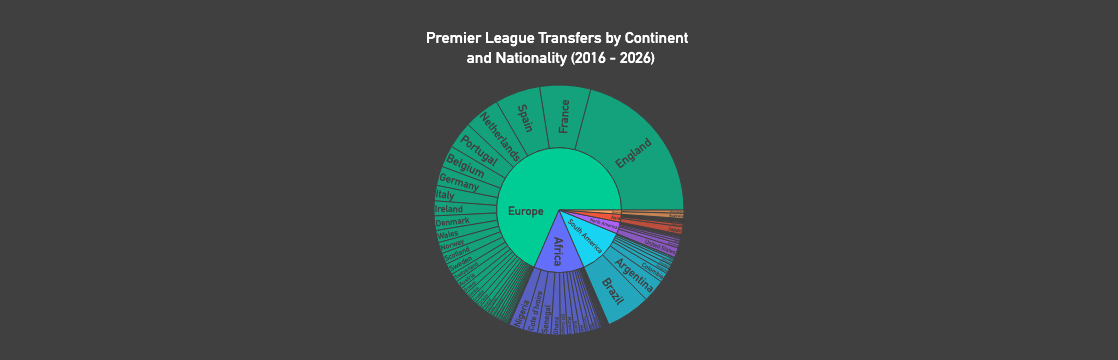

In [30]:

import pandas as pd
import plotly.express as px

# --------------------------------------------------
# 1. Prepare the data
# --------------------------------------------------

sunburst_df = (transfers_df.dropna(subset=["continent", "nationality"])
                           .groupby(["continent", "nationality"])
                           .size()
                           .reset_index(name = "transfers"))

# --------------------------------------------------
# 2. Define chart colours
# --------------------------------------------------
'''
continent_colours = {
    "Europe": "#8DBBD9",
    "South America": "#527FA4",
    "Africa": "#D18B72",
    "North America": "#88A98A",
    "Asia": "#B69AC8",
    "Oceania": "#D6B96C",
}
'''
# --------------------------------------------------
# 3. Create the sunburst chart
# --------------------------------------------------

fig = px.sunburst(sunburst_df,
                  path = ["continent", "nationality"],
                  values = "transfers",
                  color = "continent")
# --------------------------------------------------
# 4. Calculate totals for custom hover information
# --------------------------------------------------

total_transfers = int(sunburst_df["transfers"].sum())

continent_totals = (sunburst_df.groupby("continent")["transfers"]
                               .sum()
                               .to_dict())

# --------------------------------------------------
# 5. Customise hover information by node
# --------------------------------------------------

trace = fig.data[0]
hover_text = []

for label, parent, value in zip(trace.labels,
                                trace.parents,
                                trace.values):
    value = int(value)

    # Root node
    if label == "" and parent == "":
        hover_text.append(
            f"<b>All Transfers</b><br>"
            f"Transfers: {total_transfers:,}"
        )

    # Continent nodes
    elif parent == "":
        hover_text.append(
            f"<b>{label}</b><br>"
            f"Transfers: {value:,}<br>"
            f"% of all transfers: "
            f"{value / total_transfers:.2%}"
        )

    # Country nodes
    else:
        continent = parent
        continent_total = continent_totals[continent]

        hover_text.append(
            f"<b>{label}</b><br>"
            f"Transfers: {value:,}<br>"
            f"% of all transfers: "
            f"{value / total_transfers:.2%}<br>"
            f"% of continent transfers: "
            f"{value / continent_total:.2%}"
        )

trace.hovertext = hover_text
trace.hovertemplate = "%{hovertext}<extra></extra>"
trace.insidetextorientation = "radial"
trace.insidetextfont = dict(color = "#404040",
                            family = "DIN Alternate")
trace.branchvalues = "total"
trace.maxdepth = 2

# --------------------------------------------------
# 6. Style the chart
# --------------------------------------------------

fig.update_layout(title=dict(text="Premier League Transfers by Continent <br> and Nationality (2016 - 2026)",
                             x = 0.5,
                             xanchor="center",
                             font=dict(family="DIN Alternate",
                                       size=16,
                                       color="#FFFFFF")),
                             paper_bgcolor="#404040",
                             plot_bgcolor="#404040",
                             font=dict(family="DIN Alternate",
                                       color="#CCCCCC"),
                             margin=dict(t=85, b=25, l=0, r=0),
                             height=None,
                             autosize = True)

# --------------------------------------------------
# 7. Display the chart
# --------------------------------------------------

fig.show()

# --------------------------------------------------
# 8. Export file as html
# --------------------------------------------------

fig.write_html(project_folder / "figures/html/continents-sunburts.html",
              config = {"responsive" : True,
                        "displayModeBar" : False})


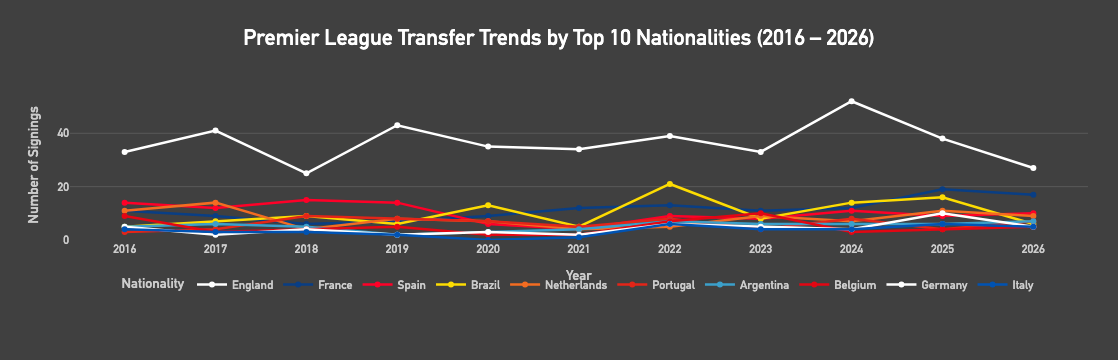

In [16]:

import pandas as pd
import plotly.express as px

# --------------------------------------------------
# 1. Prepare the data
# --------------------------------------------------

trend_df = transfers_df.dropna(subset=["season", "nationality"]).copy()

# Extract the starting year from season labels.
trend_df["year"] = (trend_df["season"].astype(str)
                                      .str.extract(r"(\d{4})", expand=False))

trend_df["year"] = pd.to_numeric(trend_df["year"], errors="coerce")

trend_df = trend_df.dropna(subset=["year"])
trend_df["year"] = trend_df["year"].astype(int)

# Keep the requested period
years = list(range(2016, 2027))

trend_df = trend_df[trend_df["year"].isin(years)]

# --------------------------------------------------
# 2. Count transfers by nationality and year
# --------------------------------------------------

yearly_transfers = (trend_df.groupby(["year", "nationality"])
                            .size()
                            .reset_index(name="transfers"))

# Find the 10 most common nationalities across
# the entire period
top_10_nations = (yearly_transfers.groupby("nationality")["transfers"]
                  .sum()
                  .nlargest(10)
                  .index
                  .tolist())

# Keep only those nationalities
trend_top10 = yearly_transfers[yearly_transfers["nationality"].isin(top_10_nations)].copy()

# --------------------------------------------------
# 3. Fill missing years with zero transfers
# --------------------------------------------------

full_index = pd.MultiIndex.from_product([years, top_10_nations],
                                        names=["year", "nationality"])

trend_top10 = (trend_top10.set_index(["year", "nationality"])
                          .reindex(full_index, fill_value=0)
                          .reset_index())

# --------------------------------------------------
# 4. Define colours for the 10 lines
# --------------------------------------------------

line_colours = [
    "#FFFFFF",
    "#093E84",
    "#FF0028",
    "#FDDC02",
    "#F36C21",
    "#E42518",
    "#3BA0CB",
    "#E30613",
    "#FFFFFF",
    "#0053B3"]

# --------------------------------------------------
# 5. Create the line chart
# --------------------------------------------------

fig = px.line(
    trend_top10,
    x="year",
    y="transfers",
    color="nationality",
    markers=True,
    category_orders={
        "year": years,
        "nationality": top_10_nations,
    },
    color_discrete_sequence=line_colours,
    custom_data=["nationality"],
)

fig.update_traces(
    line=dict(width=2.5),
    marker=dict(size=6),
    hovertemplate=(
        "<b>%{customdata[0]}</b><br>"
        "Transfers: %{y:,}"
        "<extra></extra>"
    ),
)

# --------------------------------------------------
# 6. Style the chart
# --------------------------------------------------

fig.update_layout(
    title=dict(
        text="Premier League Transfer Trends by Top 10 Nationalities (2016 – 2026)",
        x=0.5,
        xanchor="center",
        font=dict(
            family="DIN Alternate",
            size=22,
            color="#FFFFFF",
        ),
    ),
    paper_bgcolor="#404040",
    plot_bgcolor="#404040",
    font=dict(
        family="DIN Alternate",
        color="#CCCCCC",
    ),
    xaxis=dict(
        title="Year",
        tickmode="array",
        tickvals=years,
        ticktext=[str(year) for year in years],
        showgrid=False,
        zeroline=False,
        dtick=1,
    ),
    yaxis=dict(
        title="Number of Signings",
        rangemode="tozero",
        gridcolor="#595959",
        zeroline=False,
    ),
    legend=dict(
        title="Nationality",
        orientation="h",
        yanchor="top",
        y=-0.2,
        xanchor="center",
        x=0.5,
    ),
    margin=dict(t=90, b=120, l=70, r=30),
    hovermode="x unified",
    height = None,
    autosize = True)

fig.show()

# --------------------------------------------------
# 7. Export file as html
# --------------------------------------------------

fig.write_html(project_folder / "figures/html/nationality_trends.html",
               config = {"responsive" : True,
                         "displayModeBar" : False})


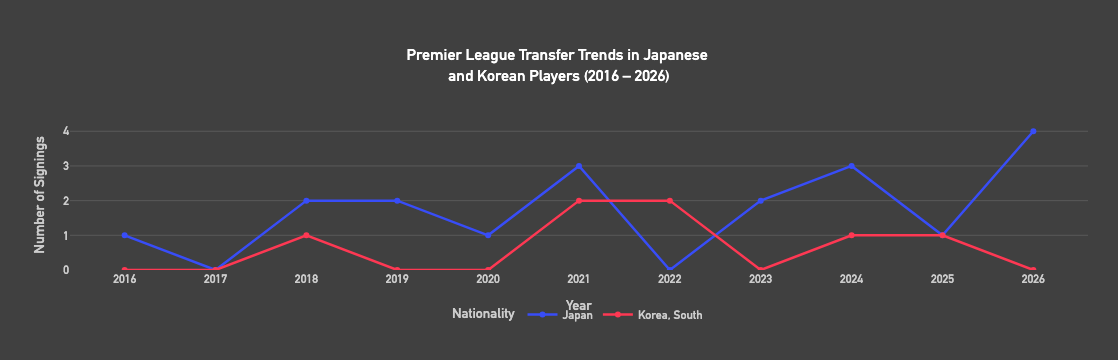

In [32]:
import pandas as pd
import plotly.express as px

# --------------------------------------------------
# 1. Prepare the data
# --------------------------------------------------

trend_df = transfers_df.dropna(subset=["season", "nationality"]).copy()

# Extract the starting year from season labels.
trend_df["year"] = (trend_df["season"].astype(str)
                                      .str.extract(r"(\d{4})", expand=False))

trend_df["year"] = pd.to_numeric(trend_df["year"], errors="coerce")

trend_df = trend_df.dropna(subset=["year"])
trend_df["year"] = trend_df["year"].astype(int)

# Keep the requested period
years = list(range(2016, 2027))

trend_df = trend_df[trend_df["year"].isin(years)]

# --------------------------------------------------
# 2. Count transfers by nationality and year
# --------------------------------------------------
asian_transfers = trend_df[trend_df["continent"] == "Asia"]

yearly_transfers = (asian_transfers.groupby(["year", "nationality"])
                            .size()
                            .reset_index(name="transfers"))

# Use Japan and Korea as the top 2 
# the entire period
top_2_nations = (yearly_transfers.groupby("nationality")["transfers"]
                  .sum()
                  .nlargest(2)
                  .index
                  .tolist())

# Keep only those nationalities
trend_top2 = yearly_transfers[yearly_transfers["nationality"].isin(top_2_nations)].copy()

# --------------------------------------------------
# 3. Fill missing years with zero transfers
# --------------------------------------------------

full_index = pd.MultiIndex.from_product([years, top_2_nations],
                                        names=["year", "nationality"])

trend_top2 = (trend_top2.set_index(["year", "nationality"])
                          .reindex(full_index, fill_value=0)
                          .reset_index())

# --------------------------------------------------
# 4. Define colours for the 10 lines
# --------------------------------------------------

line_colours = ["#384df8", "#fe3853"]
                
# --------------------------------------------------
# 5. Create the line chart
# --------------------------------------------------

fig = px.line(
    trend_top2,
    x="year",
    y="transfers",
    color="nationality",
    markers=True,
    category_orders={
        "year": years,
        "nationality": top_2_nations,
    },
    color_discrete_sequence=line_colours,
    custom_data=["nationality"],
)

fig.update_traces(
    line=dict(width=2.5),
    marker=dict(size=6),
    hovertemplate=(
        "<b>%{customdata[0]}</b><br>"
        "Transfers: %{y:,}"
        "<extra></extra>"
    ),
)

# --------------------------------------------------
# 6. Style the chart
# --------------------------------------------------

fig.update_layout(
    title=dict(
        text="Premier League Transfer Trends in Japanese <br>and Korean Players (2016 – 2026)",
        x=0.5,
        xanchor="center",
        font=dict(
            family="DIN Alternate",
            size=16,
            color="#FFFFFF",
        ),
    ),
    paper_bgcolor="#404040",
    plot_bgcolor="#404040",
    font=dict(
        family="DIN Alternate",
        color="#CCCCCC",
    ),
    xaxis=dict(
        title="Year",
        tickmode="array",
        tickvals=years,
        ticktext=[str(year) for year in years],
        showgrid=False,
        zeroline=False,
        dtick=1,
    ),
    yaxis=dict(
        title="Number of Signings",
        tickvals = trend_top2["transfers"],
        rangemode="tozero",
        gridcolor="#595959",
        zeroline=False,
    ),
    legend=dict(
        title="Nationality",
        orientation="h",
        yanchor="top",
        y=-0.2,
        xanchor="center",
        x=0.5,
    ),
    margin=dict(t=120, b=90, l=70, r=30),
    hovermode="x unified",
    height = None,
    autosize = True)

fig.show()

# --------------------------------------------------
# 7. Export file as html
# --------------------------------------------------

fig.write_html(project_folder / "figures/html/japan_and_korea_trends.html",
               config = {"responsive" : True,
                         "displayModeBar" : False})


### League Trends
After investigating transfers by nationality over the last decade we have uncovered that Asian transfers account for just 2.02% of these and given the quality and success of the major nations of Korea and Japan why have more not come?

So it is clear that Premier League recruitment might overlook Asian players in general, but what about Asian domestic leagues? I would assume most transfers into the Premier League come from other major European leagues. For the asian players who eventually join the Premier League, I would assume that their development pathway takes them from their domestic league into other leagues in Europe before joining the Premier League.

So I now want to find out if there were any direct transfers straight from an Asian League to the Premier League, the common pathways into european football for asian players and hopefully this will help to understand why Premier League teams don't recruit from Asian Leagues. 

In [34]:
# ------------------------------------
# Load the transfer data with selling leagues
# ------------------------------------

import pandas as pd
from pathlib import Path

project_folder = Path.cwd().parent

transfers = pd.read_csv(project_folder / "data/cleaned/transfers_with_selling_leagues.csv")

In [36]:
# ---------------------------------------------------
# Identify unique selling countries and map codes
# ---------------------------------------------------

dealing_countries = sorted(
    transfers["dealing_country"].dropna().unique()
)

country_iso_map = {
    "Argentina": "ARG",
    "Armenia": "ARM",
    "Australia": "AUS",
    "Austria": "AUT",
    "Belgium": "BEL",
    "Bosnia-Herzegovina": "BIH",
    "Brazil": "BRA",
    "China": "CHN",
    "Colombia": "COL",
    "Costa Rica": "CRI",
    "Croatia": "HRV",
    "Czech Republic": "CZE",
    "Denmark": "DNK",
    "Ecuador": "ECU",
    "Egypt": "EGY",
    "England": "GBR",
    "France": "FRA",
    "Germany": "DEU",
    "Greece": "GRC",
    "Hungary": "HUN",
    "Israel": "ISR",
    "Italy": "ITA",
    "Japan": "JPN",
    "Kazakhstan": "KAZ",
    "Korea, South": "KOR",
    "Netherlands": "NLD",
    "Norway": "NOR",
    "Paraguay": "PRY",
    "Poland": "POL",
    "Portugal": "PRT",
    "Qatar": "QAT",
    "Romania": "ROU",
    "Russia": "RUS",
    "Saudi Arabia": "SAU",
    "Scotland": "GBR",
    "Serbia": "SRB",
    "Slovenia": "SVN",
    "South Africa": "ZAF",
    "Spain": "ESP",
    "Sweden": "SWE",
    "Switzerland": "CHE",
    "Türkiye": "TUR",
    "Ukraine": "UKR",
    "United Arab Emirates": "ARE",
    "United States": "USA",
    "Uruguay": "URY",
    "Venezuela": "VEN"}


transfers["country_code"] = transfers["dealing_country"].map(country_iso_map)

In [38]:
# ---------------------------------------------------
# Handle mismatching league names
# ---------------------------------------------------
# Exclude transfers without a selling country or ISO code
map_df = transfers.dropna(
    subset=["dealing_country", "country_code"]
).copy()


# Standardise alternative names for the same division
league_aliases = {
    "LaLiga": "La Liga",
    "Super League Greece": "Super League 1",
    "Liga Portugal": "Primeira Liga",
    "Czech First League": "Chance Liga",
    "Jupiler Pro League": "Belgian Pro League",
    "SuperSport HNL" : "HNL",
    "Championnat National" : "Ligue 2",
    "Super League" : "Swiss Super League",
    "Austrian Bundesliga" : "Bundesliga",
    "Ukranian Premier League" : "Premier Liga",
    "Segunda División" : "La Liga 2",
    "LaLiga2" : "La Liga 2",
    "Keuken Kampioen Divisie" : "Eerste Divisie",
    "Nemzeti Bajnokság" : "Nemzeti Bajnokság I",
    "Super liga Srbije" : "Serbian SuperLiga",
    "Superliga" : "Danish Superliga"
}

map_df["league_name"] = (
    map_df["league_name"].replace(league_aliases)
)

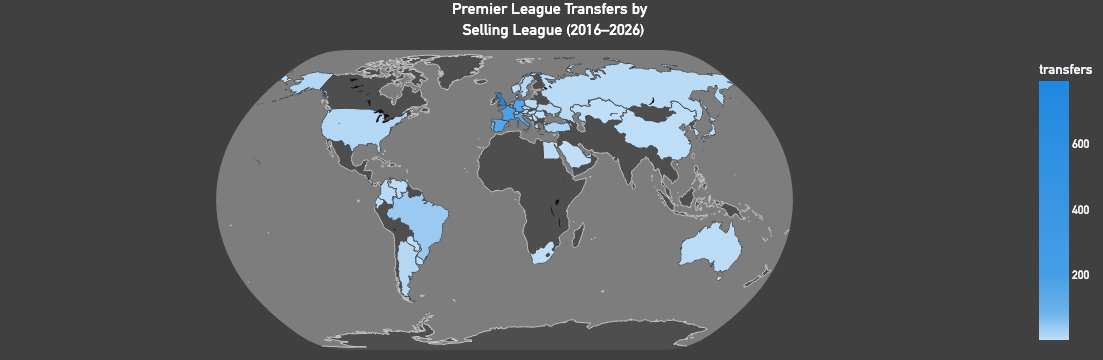

In [40]:
import pandas as pd
import plotly.express as px

# --------------------------------------------------
# 1. Prepare the data
# --------------------------------------------------

# Ensure fees are numeric
map_df["fee"] = pd.to_numeric(map_df["fee"], errors="coerce")

# Keep transfers with no known selling division under a clear label
map_df["league_name"] = map_df["league_name"].fillna("Unknown division")

# Aggregate by selling country
map_stats = (
    map_df.groupby("country_code")
    .agg(
        transfers=("player_name", "size"),
        avg_fee=("fee", "mean")
    )
    .reset_index()
)

# --------------------------------------------------
# 2. Create the division breakdown for each country
# --------------------------------------------------

division_stats = (
    map_df.groupby(["country_code", "league_name"])
    .agg(
        transfers=("player_name", "size"),
        avg_fee=("fee", "mean")
    )
    .reset_index()
    .sort_values(
        ["country_code", "transfers"],
        ascending=[True, False]
    )
)

# Keep the top 3 divisions for each country
top_3_divisions = division_stats.groupby("country_code").head(3)

# Format the division breakdown for the hover
# Format top 3 divisions for the hover
division_breakdowns = (
    top_3_divisions
    .groupby("country_code")
    .apply(
        lambda group: "<br><br>".join(
            f"<b>{row['league_name']}</b><br>"
            f"{row['transfers']} transfers &nbsp;&nbsp; "
            f"€{row['avg_fee']:,.0f} average fee"
            if pd.notna(row["avg_fee"])
            else f"<b>{row['league_name']}</b><br>"
                 f"{row['transfers']} transfers &nbsp;&nbsp; "
                 "Average fee N/A"
            for _, row in group.iterrows()
        ),
        include_groups=False
    )
    .rename("division_breakdown")
    .reset_index()
)

map_stats = map_stats.drop(
    columns=["division_breakdown"],
    errors="ignore"
).merge(
    division_breakdowns,
    on="country_code",
    how="left"
)

# Map ISO codes to selling country names
country_names = (
    map_df.drop_duplicates("country_code")
    .set_index("country_code")["dealing_country"]
    .to_dict()
)

map_stats["country_name"] = map_stats["country_code"].map(country_names)

# England and Scotland both map to GBR, so label that combined region UK
map_stats.loc[
    map_stats["country_code"] == "GBR", "country_name"
] = "United Kingdom"

# --------------------------------------------------
# 3. Create the map
# --------------------------------------------------

fig = px.choropleth(
    map_stats,
    locations="country_code",
    locationmode="ISO-3",
    color="transfers",
    color_continuous_scale=[
        [0.0, "#C0DEF6"],
        [0.05, "#98C9F1"],
        [0.1, "#6FB4EB"],
        [0.25, "#479EE6"],
        [1.0, "#1F89E0"]
    ],
    custom_data=[
    "country_name",
    "transfers",
    "avg_fee",
    "division_breakdown"],
    
    projection="natural earth"
)

# --------------------------------------------------
# 4. Customise hover information
# --------------------------------------------------

fig.update_traces(
    hovertemplate=(
        "<b>%{customdata[0]}</b><br>"
        "Total transfers: %{customdata[1]:,.0f}"
        "<br><br>"
        "%{customdata[3]}"
        "<extra></extra>"
    )
)
# --------------------------------------------------
# 5. Style the chart
# --------------------------------------------------

fig.update_layout(
    font_family="DIN Alternate",
    template="plotly_dark",
    paper_bgcolor="#404040",
    plot_bgcolor="#404040",
    geo=dict(
        showframe=False,
        showcoastlines=True,
        coastlinecolor="#CCCCCC",
        showland=True,
        landcolor="#4E4E4E",
        showocean=True,
        oceancolor="#7D7D7D",
        bgcolor="#404040"
    ),
    title=dict(
        text="Premier League Transfers by <br> Selling League (2016–2026)",
        font=dict(
            family="DIN Alternate",
            size=16,
            color="#FFFFFF"
        ),
        x=0.5,
        xanchor="center",
        y=0.96,
        yanchor="top"
    ),
    margin=dict(l=0, r=0, t=50, b=10),
    height=None,
    autosize=True
)

# --------------------------------------------------
# 6. Export and display
# --------------------------------------------------

fig.write_html(
    project_folder / "figures/html/selling-league-map.html",
    config={"responsive": True,
            "displayModeBar" : False}
)

fig.show()

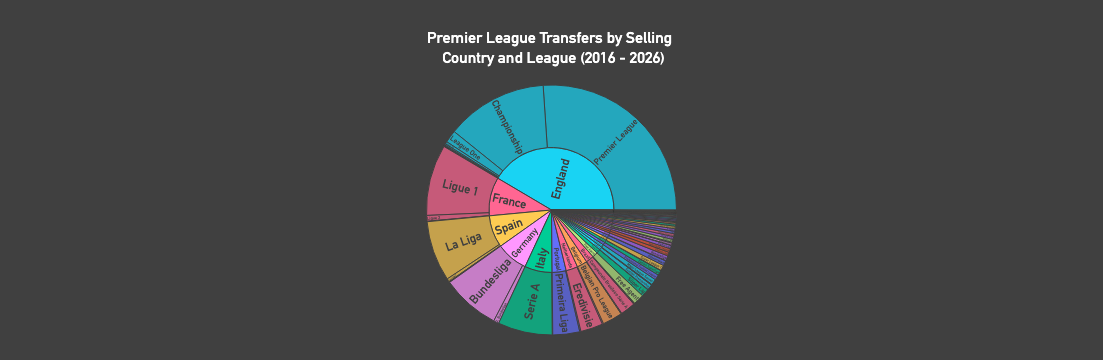

In [44]:
import pandas as pd
import plotly.express as px

# --------------------------------------------------
# 1. Prepare the data
# --------------------------------------------------

sunburst_leagues_df = transfers.copy()

sunburst_leagues_df["league_name"] = (
    sunburst_leagues_df["league_name"]
    .replace(league_aliases)
    .fillna("Free Agent")
)

sunburst_leagues_df["dealing_country"] = (
    sunburst_leagues_df["dealing_country"]
    .fillna("Free Agent")
)

sunburst_leagues_df = (
    sunburst_leagues_df
    .groupby(["dealing_country", "league_name"])
    .size()
    .reset_index(name="transfers")
)

# --------------------------------------------------
# 2. Define chart colours
# --------------------------------------------------

# --------------------------------------------------
# 3. Create the sunburst chart
# --------------------------------------------------

fig = px.sunburst(sunburst_leagues_df,
                  path = ["dealing_country", "league_name"],
                  values = "transfers",
                  color = "dealing_country")

# --------------------------------------------------
# 4. Calculate totals for custom hover information
# --------------------------------------------------

total_transfers = int(sunburst_leagues_df["transfers"].sum())

country_totals = (sunburst_leagues_df.groupby("dealing_country")["transfers"]
                               .sum()
                               .to_dict())

# --------------------------------------------------
# 5. Customise hover information by node
# --------------------------------------------------

trace = fig.data[0]
hover_text = []

for label, parent, value in zip(trace.labels,
                                trace.parents,
                                trace.values):
    value = int(value)

    # Root node
    if label == "" and parent == "":
        hover_text.append(
            f"<b>All Transfers</b><br>"
            f"Transfers: {total_transfers:,}"
        )

    # Country nodes
    elif parent == "":
        hover_text.append(
            f"<b>{label}</b><br>"
            f"{value} Transfers<br>"
            f"{value / total_transfers:.2%} of all transfers"
        )

    # League nodes
    else:
        country = parent
        country_total = country_totals[country]

        hover_text.append(
            f"<b>{label}</b><br>"
            f"{value} transfers<br>"
            f"{value / total_transfers:.2%} of all transfers<br>"
            f"{value / country_total:.2%} of country's transfers")

trace.hovertext = hover_text
trace.hovertemplate = "%{hovertext}<extra></extra>"
trace.insidetextorientation = "radial"
trace.insidetextfont = dict(color = "#404040",
                            family = "DIN Alternate")
trace.branchvalues = "total"
trace.maxdepth = 2

# --------------------------------------------------
# 6. Style the chart
# --------------------------------------------------

fig.update_layout(title=dict(text="Premier League Transfers by Selling <br> Country and League (2016 - 2026)",
                             x = 0.5,
                             xanchor="center",
                             font=dict(family="DIN Alternate",
                                       size=16,
                                       color="#FFFFFF")),
                             paper_bgcolor="#404040",
                             plot_bgcolor="#404040",
                             font=dict(family="DIN Alternate",
                                       color="#CCCCCC"),
                             margin=dict(t=85, b=25, l=0, r=0),
                             height=None,
                             autosize = True)

# --------------------------------------------------
# 7. Display the chart
# --------------------------------------------------

fig.show()

# --------------------------------------------------
# 8. Export file as html
# --------------------------------------------------

fig.write_html(project_folder / "figures/html/leagues-sunburts.html",
              config = {"responsive" : True,
                        "displayModeBar" : False})

### League strength v transfers


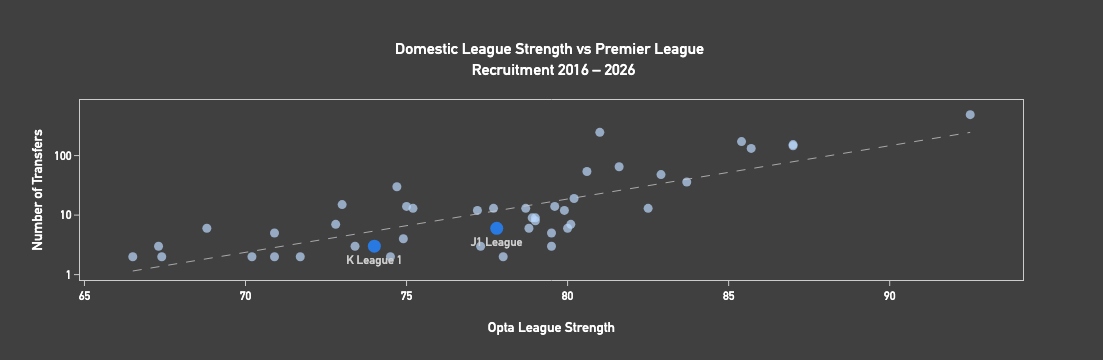

In [48]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# --------------------------------------------------
# 1. Load the data
# --------------------------------------------------
transfer_leagues_df = pd.read_csv(Path.cwd().parent / "data/cleaned/transfers_with_selling_leagues.csv")
league_strengths = pd.read_csv(Path.cwd().parent / "data/cleaned/league_strength.csv")

# --------------------------------------------------
# 2. Standardise league names
# --------------------------------------------------

# Standardise alternative names for the same division
league_aliases = {
    "LaLiga": "La Liga",
    "Super League Greece": "Super League 1",
    "Liga Portugal": "Primeira Liga",
    "Czech First League": "Chance Liga",
    "Jupiler Pro League": "Belgian Pro League",
    "SuperSport HNL" : "HNL",
    "Championnat National" : "Ligue 2",
    "Super League" : "Swiss Super League",
    "Austrian Bundesliga" : "Bundesliga",
    "Ukranian Premier League" : "Premier Liga",
    "Segunda División" : "La Liga 2",
    "LaLiga2" : "La Liga 2",
    "Keuken Kampioen Divisie" : "Eerste Divisie",
    "Nemzeti Bajnokság" : "Nemzeti Bajnokság I",
    "Super liga Srbije" : "Serbian SuperLiga",
    "Superliga" : "Danish Superliga"
}

transfer_leagues_df["league_name"] = transfer_leagues_df["league_name"].replace(league_aliases)

# --------------------------------------------------
# 2. Merge league strengths
# --------------------------------------------------
transfer_leagues_df = transfer_leagues_df.merge(league_strengths,
                                               on = "league_name",
                                               how = "left").copy()

# --------------------------------------------------
# 3. Drop nan values
# --------------------------------------------------
transfer_leagues_df = transfer_leagues_df[transfer_leagues_df["league_strength"].notna()].copy()

# --------------------------------------------------
# 4. Group by league and count
# --------------------------------------------------
league_transfers_df = (
    transfer_leagues_df
    .groupby(["league_name", "league_strength"])
    .size()
    .reset_index(name="number_of_transfers")
)
league_transfers_df = league_transfers_df[league_transfers_df["number_of_transfers"] > 1]

# --------------------------------------------------
# 5. Plot
# --------------------------------------------------

import numpy as np
import plotly.graph_objects as go
from sklearn.metrics import r2_score

highlight_leagues = ["J1 League", "K League 1"]

highlight_df = league_transfers_df[
    league_transfers_df["league_name"].isin(highlight_leagues)
]

other_df = league_transfers_df[
    ~league_transfers_df["league_name"].isin(highlight_leagues)
]

fig = go.Figure()

# Other leagues
fig.add_trace(go.Scatter(
    x=other_df["league_strength"],
    y=other_df["number_of_transfers"],
    mode="markers",
    name="Other leagues",
    customdata=other_df[["league_name"]].to_numpy(),
    marker=dict(
        color="#BBD7FC",
        size=9,
        opacity=0.7
    ),
    hovertemplate=(
        "<b>%{customdata[0]}</b><br>"
        "Opta league strength: %{x}<br>"
        "Premier League signings: %{y}"
        "<extra></extra>"
    )
))

# Highlighted leagues
fig.add_trace(go.Scatter(
    x=highlight_df["league_strength"],
    y=highlight_df["number_of_transfers"],
    mode="markers+text",
    name="J1 / K League 1",
    text=highlight_df["league_name"],
    textposition="bottom center",
    textfont=dict(
        color="#CCCCCC",
        size=12
    ),
    marker=dict(
        color="#2780F5",
        size=13,
        opacity=0.9
    ),
    hovertemplate=(
        "<b>%{text}</b><br>"
        "Opta league strength: %{x}<br>"
        "Premier League signings: %{y}"
        "<extra></extra>"
    )
))

# Regression line
x = league_transfers_df["league_strength"].astype(float)
y = league_transfers_df["number_of_transfers"].astype(float)

log_y = np.log10(y)
slope, intercept = np.polyfit(x, log_y, 1)

x_line = np.linspace(x.min(), x.max(), 100)
y_line = 10 ** (slope * x_line + intercept)

log_y_pred = slope * x + intercept
r2 = r2_score(log_y, log_y_pred)

fig.add_trace(go.Scatter(
    x=x_line,
    y=y_line,
    mode="lines",
    name=f"Log-linear fit (R² = {r2:.3f})",
    line=dict(
        color="#CCCCCC",
        width=0.75,
        dash="dash"
    ),
    hoverinfo="skip"
))

# Layout
fig.update_layout(
    height=None,
    autosize = True,
    
    title=dict(
        text="Domestic League Strength vs Premier League <br> Recruitment 2016 – 2026",
        x=0.5,
        y = 0.85,
        font=dict(size=16, color="#FFFFFF")
    ),
    
    paper_bgcolor="#404040",
    plot_bgcolor="#404040",
    font=dict(
        family="DIN Alternate",
        color="#FFFFFF"
    ),
    
    showlegend=False,
    
    hoverlabel=dict(
        bgcolor="#96979E",
        font = dict(family = "DIN Alternate",
                    color = "#FFFFFF",
                    size = 12)
    ),
    template="none"
)

fig.update_xaxes(
    title="Opta League Strength",
    showgrid=False,
    zeroline=False,
    showline=True,
    mirror = True,
    linecolor="#CCCCCC",
    linewidth=1,
    ticks="outside",
    tickcolor="#CCCCCC"
)

fig.update_yaxes(
    title="Number of Transfers",
    type="log",
    tickmode="array",
    tickvals=[1, 10, 100, 1000],
    ticktext=["1", "10", "100", "1,000"],
    showgrid=False,
    minor=dict(ticks=""),
    mirror = True,
    zeroline=False,
    showline=True,
    linecolor="#CCCCCC",
    linewidth=1,
    ticks="outside",
    tickcolor="#CCCCCC"
)

fig.show()

fig.write_html(Path.cwd().parent / "figures/html/league-strength.html",
              config = {"responsive" : True,
                        "displayModeBar": False})

In [100]:
print(league_transfers_df[league_transfers_df["league_strength"].between(73,79)].sort_values("league_strength", ascending = False))

                    league_name  league_strength  number_of_transfers
63           Swiss Super League             79.0                    9
31                    La Liga 2             79.0                    8
16                  Chance Liga             78.9                    9
25                          HNL             78.8                    6
60               Super League 1             78.7                   13
43  Paraguayan Primera División             78.0                    2
27                    J1 League             77.8                    6
2                 2. Bundesliga             77.7                   13
41          Nemzeti Bajnokság I             77.3                    3
4                   Allsvenskan             77.2                   12
54         Scottish Premiership             75.2                   13
37                      Ligue 2             75.0                   14
22      Egyptian Premier League             74.9                    4
32                  